In [2]:
import pandas as pd
df = pd.read_csv("C:/Users/Administrator/Desktop/MY PROJECT/Salary_dataset.csv")

print(f"Roes: {df. shape[0]}, columns: {df.shape[1]}")
print(f"column names: {list(df.columns)}")
df.head()


Roes: 70, columns: 2
column names: ['YearsExperience', 'Salary']


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,NaN,43526.0
4,2.3,39892.0


In [2]:
print("--- 2.1 Basic statistics ---")
display(df.describe())

--- 2.1 Basic statistics ---


,YearsExperience,Salary
count,64.000000,67.000000
mean,5.300000,73702.298507
std,2.770823,26208.857961
min,1.200000,37732.000000
25%,3.300000,56643.000000
50%,4.100000,63219.000000
75%,7.400000,96107.500000
max,10.600000,122392.000000


In [4]:
print("---2.2 Data types---")
print(df.dtypes)

---2.2 Data types---
YearsExperience    float64
Salary             float64
dtype: object


In [19]:
print("---2.3 Missing values per solumn----")
print(df.isna().sum())

---2.3 Missing values per solumn----
YearsExperience    6
Salary             3
dtype: int64


In [20]:
print("--- 2.4 Duplicate rows ---")
print (f"Duplicate rows: {df.duplicated().sum()}")
print ("Duplicate rows: ")


--- 2.4 Duplicate rows ---
Duplicate rows: 32
Duplicate rows: 


In [21]:
print("--- 2.5 Unique values ---")
for col in df.columns:
  print(f"{col}: {df[col].nunique()}")

--- 2.5 Unique values ---
YearsExperience: 29
Salary: 31


In [24]:
# --- 3.1 Fix data types ---
# Purpose: guarantee both columns are truly numeric. Any value that can't be converted
# (e.g. a stray string like "N/A") becomes NaN instead of silently breaking downstream math.
df["YearsExperience"] = pd.to_numeric(df["YearsExperience"], errors="coerce")  # coerce = invalid values become NaN rather than raising an error
df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")  # coerce =If a value cannot be converted to a number, don't stop the program. Change that value to NaN instead.
print("3.1 Data types coerced to numeric")

3.1 Data types coerced to numeric


In [25]:
# --- 3.2 Remove duplicates ---
before = len(df)                # counts the total number of rows in your DataFrame
df = df.drop_duplicates()       # keeps the first occurrence of each duplicated row, drops the rest(looks for rows that are exactly the same and removes the repeated copies.
print(f"3.2 Removed {before - len(df)} duplicate rows") #Calculate how many were removed

3.2 Removed 32 duplicate rows


In [26]:
# --- 3.3 Handle missing values (imputation) ---
# Purpose: most ML algorithms cannot handle NaN directly, so missing values must be filled in
# with a reasonable estimate rather than dropped (which would throw away otherwise-good data).
missing=df.isna().sum().sum()  # total count of missing cells, for reporting
df["YearsExperience"] = df["YearsExperience"].fillna(df["YearsExperience"].median())  # median: robust to outliers
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())                               # mean: fine here since Salary isn't heavily skewed
print(f"3.3 Filled {missing} missing values (median for YearsExperience, mean for Salary)")

3.3 Filled 9 missing values (median for YearsExperience, mean for Salary)


In [27]:
def remove_outliers(data, col):
    Q1 = data[col].quantile(0.25)       # 25th percentile — the "lower edge" of the typical range
    Q3 = data[col].quantile(0.75)       # 75th percentile — the "upper edge" of the typical range
    IQR = Q3 - Q1                       # interquartile range: the spread of the middle 50% of the data
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR  # standard 1.5x IQR fences used to flag outliers
    before = len(data)                  # row count before filtering, for reporting
    data = data[(data[col] >= lower) & (data[col] <= upper)]  # keep only rows within the acceptable range
    print(f"   {col}: removed {before - len(data)} outliers (bounds {lower:.1f} to {upper:.1f})")
    return data

print("3.4 Outlier removal (IQR):")
df = remove_outliers(df, "YearsExperience")  # apply outlier filtering to each numeric column independently
df = remove_outliers(df, "Salary")

print(f"\nFinal shape after cleaning: {df.shape}")  # sanity check on how much data survived cleaning

3.4 Outlier removal (IQR):
   YearsExperience: removed 0 outliers (bounds -2.1 to 12.7)
   Salary: removed 0 outliers (bounds -3981.8 to 157894.2)

Final shape after cleaning: (38, 2)


In [28]:
df.to_csv("cleaned_dataset.csv", index=False)  # checkpoint the cleaned dataset
print("cleaned_dataset.csv")

cleaned_dataset.csv


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [32]:
df.to_csv("cleaned_dataset.csv", index=False)  # checkpoint the cleaned dataset
dataset= pd.read_csv("cleaned_dataset.csv")
print(dataset)

    YearsExperience         Salary
0               1.2   39344.000000
1               1.4   46206.000000
2               1.6   37732.000000
3               4.8   43526.000000
4               2.3   39892.000000
5               3.0   56643.000000
6               3.1   60151.000000
7               3.3   54446.000000
8               3.3   64446.000000
9               3.8   57190.000000
10              4.0   63219.000000
11              4.1   55795.000000
12              4.1   56958.000000
13              4.2   57082.000000
14              4.6   61112.000000
15              5.0   74251.085714
16              5.2   66030.000000
17              5.4   83089.000000
18              6.0   81364.000000
19              6.1   93941.000000
20              6.9   91739.000000
21              7.2   98274.000000
22              4.8  101303.000000
23              8.3  113813.000000
24              8.8  109432.000000
25              9.1  105583.000000
26              9.6  116970.000000
27              9.7 

In [33]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  38 non-null     float64
 1   Salary           38 non-null     float64
dtypes: float64(2)
memory usage: 740.0 bytes


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [35]:
x=dataset[['YearsExperience']]
y= dataset[['Salary']]
print("feature shape",x.shape)
print("target shape", y.shape)

feature shape (38, 1)
target shape (38, 1)


In [36]:
x_train, x_test, y_train, y_test= train_test_split(x,y, test_size=0.2, random_state=0)
print('training samples', len(x_train))
print('testing sample', len(x_test))

training samples 30
testing sample 8


In [37]:
model= LinearRegression()
fitted_model= model.fit(x_train,y_train)

In [38]:
y_prediction = model.predict(x_test)
print('predicted salary values')
print(y_prediction)

predicted salary values
[[ 68076.39370373]
 [115372.90202201]
 [ 71338.22186361]
 [ 69707.30778367]
 [ 62368.19442393]
 [ 85200.9915431 ]
 [107218.33162231]
 [ 61552.73738396]]


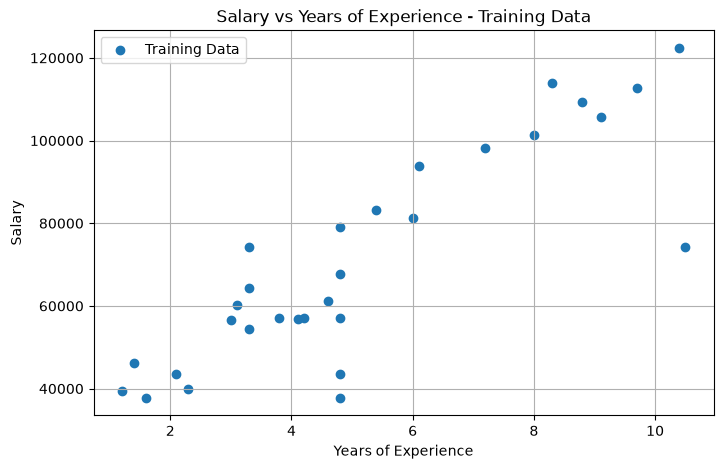

In [39]:
plt.figure(figsize=(8,5))
# plt.scatter(x_test['YearsExperience'], y_train['Salary'], label='Training Data')
plt.scatter(x_train['YearsExperience'], y_train['Salary'], label='Training Data')
plt.title('Salary vs Years of Experience - Training Data')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

In [40]:
import pickle

filename= 'Salary_linear_regression_model.sav'
pickle.dump(model, open(filename,'wb'))
print('Model saved as:', filename)

Model saved as: Salary_linear_regression_model.sav


In [41]:
loaded_model=pickle.load(open('Salary_linear_regression_model.sav','rb'))
print('saved model loaded successfully')

saved model loaded successfully


In [42]:
new_experience = 3.0
new_data= pd.DataFrame({'YearsExperience':[new_experience]})
predicted_salary= loaded_model.predict(new_data)[0][0]

print(f'Years of Experience:{new_experience}')
print(f'Predicted Salary: {predicted_salary:.2f}')

Years of Experience:3.0
Predicted Salary: 53398.17
